In [ ]:
import numpy as np
import os
from zpyhelper.filesys import checkdir
import json
import sys
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
import pandas as pd
from joblib import dump,load
from scripts.Exp1_fmri.plotting_utils import gen_pval_annot

project_path = r'E:\pirate_fmri\Analysis'
sys.path.append(project_path)
import warnings
warnings.simplefilter('ignore', category=FutureWarning)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' # silent TF GPU warnings

# Load experiment metatdata: participant list etc.
study_scripts = os.path.join(project_path,'scripts','Exp1_fmri')
with open(os.path.join(study_scripts,'pirate_defaults.json')) as f:
    pirate_defaults = json.load(f)
    subid_list = pirate_defaults['participants']['validids']
    nongeneralizers = pirate_defaults['participants']["nongeneralizerids"]
    generalizers    = pirate_defaults['participants']["generalizerids"]
print(f"N_participants = {len(subid_list)}")


# Define path: note that we are running this on wsl, so the scripts we have copied over to wsl but the data is still on the windows side
raw_img_type = "onlyrealigned"
processed_data_dir = f"e:/pirate_fmri/Analysis/data/Exp1_fmri/fmri/deepmreye/processed/{raw_img_type}/"
decoding_res_dir = f"e:/pirate_fmri/Analysis/data/Exp1_fmri/fmri/deepmreye/results/{raw_img_type}/"

ROIRSAdir = os.path.join(project_path,"data","Exp1_fmri", "fmri", "ROIdata")

import matplotlib as mpl
font_paths = mpl.font_manager.findSystemFonts()
mpl.font_manager.get_font_names()
sns.set_style('white',rc = dict(font='Arial'))  # set font globally for seaborn


N_participants = 56


# Group Averaged Lagged correlations

## across the whole timeseries

In [2]:
# load the timecourse of experiment to see if the gaze predictions make sense

tscorr_dir = os.path.join(decoding_res_dir,'treasurehunt_lag_correlation')
lag_correlation_df = pd.read_csv(os.path.join(tscorr_dir,'lag_correlations_allsubs.csv'))
lag_correlation_df = lag_correlation_df[lag_correlation_df["pretrainedmodel"]=="m7_multiDS1to5"].copy()
lag_correlation_df["subgroup"] = lag_correlation_df["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
lag_correlation_df_run_ave = lag_correlation_df.groupby(['subid','pretrainedmodel', 'taskname', 'compute_method','lag_sec', 'lag_TR'])[
    ['stimcorr_x', 'stimcorr_y', 'respstcorr_x', 'respstcorr_y','respedcorr_x', 'respedcorr_y']].mean().reset_index()
lag_correlation_df_run_ave["subgroup"] = lag_correlation_df_run_ave["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
lag_correlation_df_run_ave

,subid,pretrainedmodel,taskname,compute_method,lag_sec,lag_TR,stimcorr_x,stimcorr_y,respstcorr_x,respstcorr_y,respedcorr_x,respedcorr_y,subgroup
0,sub001,m7_multiDS1to5,piratenavigation,median,-17.300,-10.0,-0.051707,-0.025003,-0.063202,-0.033465,0.104209,-0.139149,Generalizer
1,sub001,m7_multiDS1to5,piratenavigation,median,-15.570,-9.0,-0.064286,-0.050900,-0.057051,0.035661,0.013612,0.042353,Generalizer
2,sub001,m7_multiDS1to5,piratenavigation,median,-13.840,-8.0,0.004702,0.032897,0.021529,0.059881,-0.063129,-0.127326,Generalizer
3,sub001,m7_multiDS1to5,piratenavigation,median,-12.110,-7.0,-0.070387,-0.003800,-0.097126,-0.069690,-0.101258,0.168336,Generalizer
4,sub001,m7_multiDS1to5,piratenavigation,median,-10.380,-6.0,0.011129,-0.018674,-0.058827,-0.073525,-0.098201,0.003606,Generalizer
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12427,sub130,m7_multiDS1to5,piratenavigation,subTRsamples,16.608,9.6,-0.076345,-0.000322,0.219493,0.072954,-0.130403,-0.113798,Generalizer
12428,sub130,m7_multiDS1to5,piratenavigation,subTRsamples,16.781,9.7,-0.066869,-0.006457,0.221724,0.059728,-0.095970,-0.121679,Generalizer
12429,sub130,m7_multiDS1to5,piratenavigation,subTRsamples,16.954,9.8,-0.062147,-0.016809,0.162691,0.076397,-0.116332,-0.123751,Generalizer
12430,sub130,m7_multiDS1to5,piratenavigation,subTRsamples,17.127,9.9,-0.048008,-0.031475,0.162611,0.124528,-0.066023,-0.110701,Generalizer


In [3]:
lag_correlation_df.columns

Index(['lag_TR', 'lag_sec', 'stimcorr_x', 'stimcorr_y', 'respstcorr_x',
       'respstcorr_y', 'respedcorr_x', 'respedcorr_y', 'subid', 'run',
       'pretrainedmodel', 'taskname', 'max_stimcorr_lag_x',
       'max_stimcorr_lag_y', 'max_respstcorr_lag_x', 'max_respstcorr_lag_y',
       'max_respedcorr_lag_x', 'max_respedcorr_lag_y', 'compute_method',
       'subgroup'],
      dtype='object')

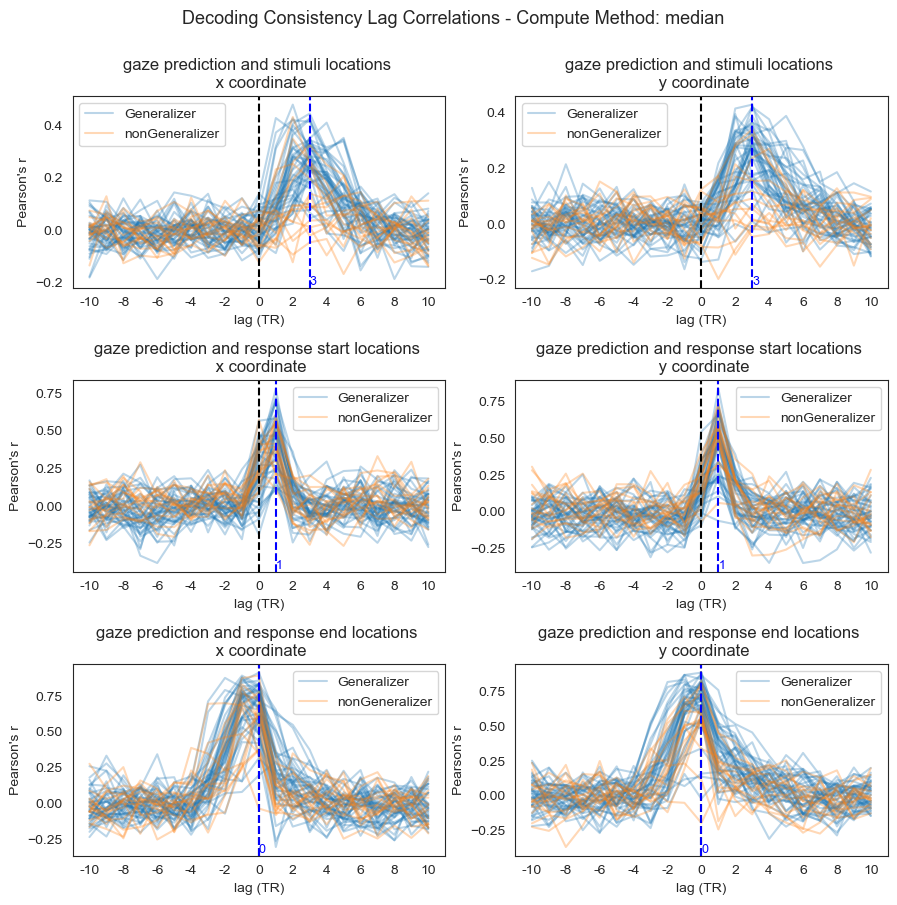

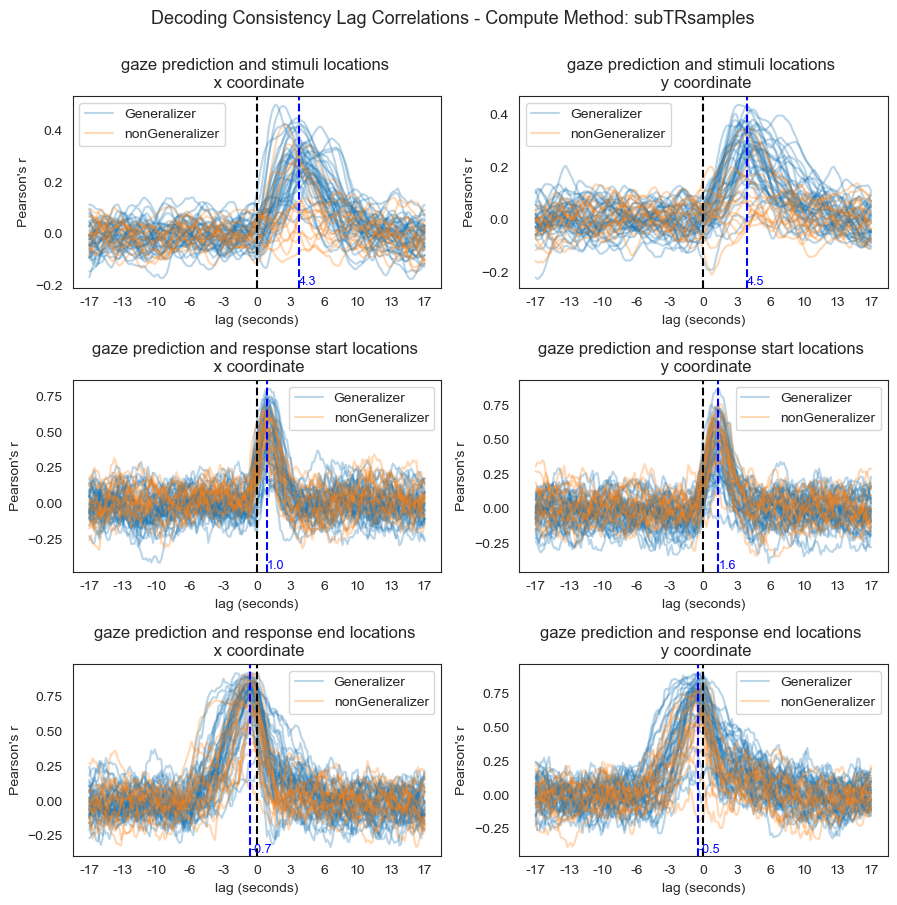

In [4]:
# plot mean correlation vs lag for each task events, for x and y separately, for each participant
events = {
    "stimuli locations": "stimcorr",
    "response start locations": "respstcorr",
    "response end locations": "respedcorr"
}
for compute_method in lag_correlation_df_run_ave["compute_method"].unique():
    figdf = lag_correlation_df_run_ave[lag_correlation_df_run_ave["compute_method"]==compute_method].copy()
    if compute_method == "median":
        xlabel="lag (TR)"
        xvar = "lag_TR"
        xticks = np.arange(-10,11,2)
    elif compute_method == "subTRsamples":
        xlabel="lag (seconds)"
        xvar = "lag_sec"
        min_lag_s = figdf[xvar].min()
        max_lag_s = figdf[xvar].max()
        delta  = (max_lag_s - min_lag_s)/10
        xticks = np.arange(min_lag_s, max_lag_s+1, delta)
    xticklabels = [str(int(x)) for x in xticks]

    fig, axes = plt.subplots(len(events),2, figsize=(9,len(events)*3),squeeze=False)
    for k, (event_name, event_prefix) in enumerate(events.items()):
        axdf = figdf.copy()
        assert axdf["pretrainedmodel"].nunique() == 1, "More than one pretrained model found in the dataframe!"
        for j,correlation_type in enumerate([f'{event_prefix}_x',f'{event_prefix}_y']):
            ax = axes[k,j]
            sns.lineplot(data=axdf, x=xvar, y=correlation_type, units="subid", estimator=None, hue="subgroup", ax=ax, alpha=0.3)
            ax.legend(title="")
            ax.axvline(x=0, color='black', linestyle='--')
            ax.set_title(f"gaze prediction and {event_name} \n {correlation_type[-1]} coordinate")
            ax.set_xlabel(xlabel)
            ax.set_ylabel("Pearson's r")
            ax.set_xticks(xticks,labels=xticklabels)
            
            mean_corrs = axdf.groupby(xvar)[correlation_type].mean().values
            lags = axdf.groupby(xvar)[xvar].mean().values
            max_corr_idx = np.argmax(mean_corrs)
            max_corr_lag = lags[max_corr_idx]
            # mark the maximum correlation points using vertical lines
            ax.axvline(x=max_corr_lag, linestyle='--', color='blue')
            # add a text at the bottom of x-axis at the max_corr_lag position
            ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.1f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                    ha='left', va='bottom', fontsize=9, color='blue')
    fig.suptitle(f"Decoding Consistency Lag Correlations - Compute Method: {compute_method}", fontsize=13, y =1)
    fig.tight_layout()

In [5]:
mean_corrs = axdf.groupby([xvar, "subgroup"])[correlation_type].mean().unstack().values
lags = axdf.groupby(xvar)[xvar].mean().values
max_corr_idx = np.argmax(mean_corrs, axis=0)
max_corr_lag = lags[max_corr_idx]

In [6]:
max_corr_lag

array([-0.519, -0.346])

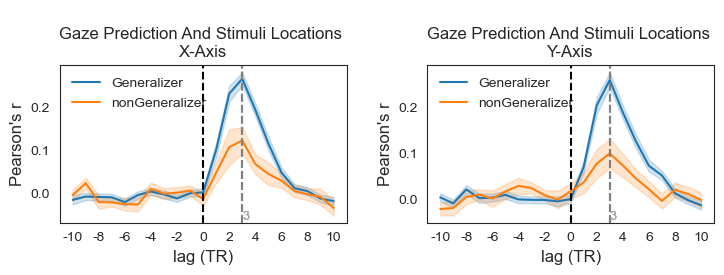

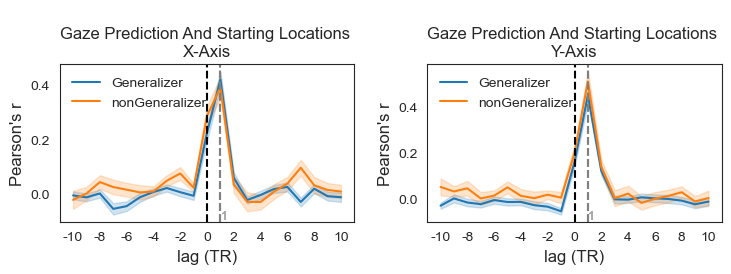

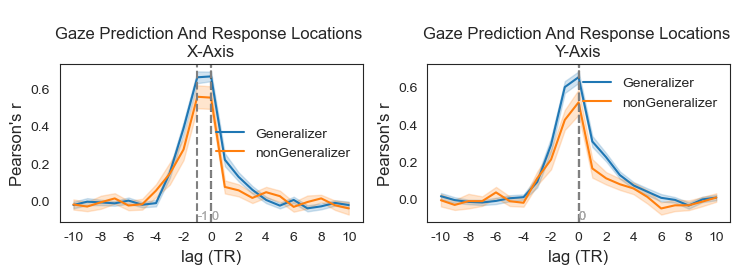

In [7]:
# plot mean correlation vs lag for each task events, for x and y separately
events = {
    "stimuli locations": "stimcorr",
    "starting locations": "respstcorr",
    "response locations": "respedcorr"
}
for compute_method in ["median"]:#lag_correlation_df_run_ave["compute_method"].unique():
    figdf = lag_correlation_df_run_ave[lag_correlation_df_run_ave["compute_method"]==compute_method].copy()
    if compute_method == "median":
        xlabel="lag (TR)"
        xvar = "lag_TR"
        xticks = np.arange(-10,11,2)
    elif compute_method == "subTRsamples":
        xlabel="lag (seconds)"
        xvar = "lag_sec"
        min_lag_s = figdf[xvar].min()
        max_lag_s = figdf[xvar].max()
        delta  = (max_lag_s - min_lag_s)/10
        xticks = np.arange(min_lag_s, max_lag_s+1, delta)
    xticklabels = [str(int(x)) for x in xticks]

    for k, (event_name, event_prefix) in enumerate(events.items()):
        fig, axes = plt.subplots(1,2, figsize=(7.5,3),squeeze=False)
        axdf = figdf.copy()
        assert axdf["pretrainedmodel"].nunique() == 1, "More than one pretrained model found in the dataframe!"
        for j,correlation_type in enumerate([f'{event_prefix}_x',f'{event_prefix}_y']):
            ax = axes[0,j]
            sns.lineplot(data=axdf, x=xvar, y=correlation_type, hue="subgroup", errorbar="se",ax=ax, alpha=1)
            ax.legend(title="",frameon=False)
            ax.axvline(x=0, color='black', linestyle='--')
            axtitle=f"\ngaze prediction and {event_name} \n{correlation_type[-1]}-axis"
            ax.set_title(axtitle.title())
            ax.set_xlabel(xlabel, fontsize=12)
            ax.set_ylabel("Pearson's r", fontsize=12)
            ax.set_xticks(xticks,labels=xticklabels)
            
            mean_corrs = axdf.groupby([xvar, "subgroup"])[correlation_type].mean().unstack().values
            lags = axdf.groupby(xvar)[xvar].mean().values
            max_corr_idx = np.argmax(mean_corrs, axis=0)
            max_corr_lag = lags[max_corr_idx]
            # mark the maximum correlation points using vertical lines
            for m in max_corr_lag:
                ax.axvline(x=m, linestyle='--', color='grey')
                # add a text at the bottom of x-axis at the max_corr_lag position
                for m in max_corr_lag:
                    ax.text(m, ax.get_ylim()[0], f"{m:.1f}" if compute_method=="subTRsamples" else f"{int(m)}" , 
                            ha='left', va='bottom', fontsize=9, color='darkgrey')
    #fig.suptitle(f"Compute Method: {compute_method}", fontsize=13)
        fig.suptitle(f"", fontsize=13)
        fig.tight_layout()

## At timepoints with or without response

In [8]:
# load the timecourse of experiment to see if the gaze predictions make sense
sttscorr_dir = os.path.join(decoding_res_dir,'treasurehunt_lag_correlation_splittrialtypes')
splitttype_lag_correlation_df = pd.read_csv(os.path.join(sttscorr_dir,'splittrialtype_lag_correlations_allsubs.csv'))
splitttype_lag_correlation_df = splitttype_lag_correlation_df[splitttype_lag_correlation_df["pretrainedmodel"]=="m7_multiDS1to5"].copy()
splitttype_lag_correlation_df["subgroup"] = splitttype_lag_correlation_df["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
splitttype_lag_correlation_df["trial_type"] = pd.Categorical(
    splitttype_lag_correlation_df["trial_type"].map({"with_response":"response trials", "without_response":"no-response trials"}),
    categories=["response trials","no-response trials"], ordered=True
)



In [9]:
figdf

,subid,pretrainedmodel,taskname,compute_method,lag_sec,lag_TR,stimcorr_x,stimcorr_y,respstcorr_x,respstcorr_y,respedcorr_x,respedcorr_y,subgroup
0,sub001,m7_multiDS1to5,piratenavigation,median,-17.30,-10.0,-0.051707,-0.025003,-0.063202,-0.033465,0.104209,-0.139149,Generalizer
1,sub001,m7_multiDS1to5,piratenavigation,median,-15.57,-9.0,-0.064286,-0.050900,-0.057051,0.035661,0.013612,0.042353,Generalizer
2,sub001,m7_multiDS1to5,piratenavigation,median,-13.84,-8.0,0.004702,0.032897,0.021529,0.059881,-0.063129,-0.127326,Generalizer
3,sub001,m7_multiDS1to5,piratenavigation,median,-12.11,-7.0,-0.070387,-0.003800,-0.097126,-0.069690,-0.101258,0.168336,Generalizer
4,sub001,m7_multiDS1to5,piratenavigation,median,-10.38,-6.0,0.011129,-0.018674,-0.058827,-0.073525,-0.098201,0.003606,Generalizer
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12226,sub130,m7_multiDS1to5,piratenavigation,median,10.38,6.0,0.041293,0.003746,-0.013715,-0.033381,-0.164988,-0.135420,Generalizer
12227,sub130,m7_multiDS1to5,piratenavigation,median,12.11,7.0,-0.016756,-0.006182,-0.099838,0.033300,0.125146,-0.176226,Generalizer
12228,sub130,m7_multiDS1to5,piratenavigation,median,13.84,8.0,0.007038,-0.050237,-0.001265,0.068830,-0.007938,-0.262129,Generalizer
12229,sub130,m7_multiDS1to5,piratenavigation,median,15.57,9.0,-0.047312,-0.092847,0.195973,0.104656,-0.159679,-0.120730,Generalizer


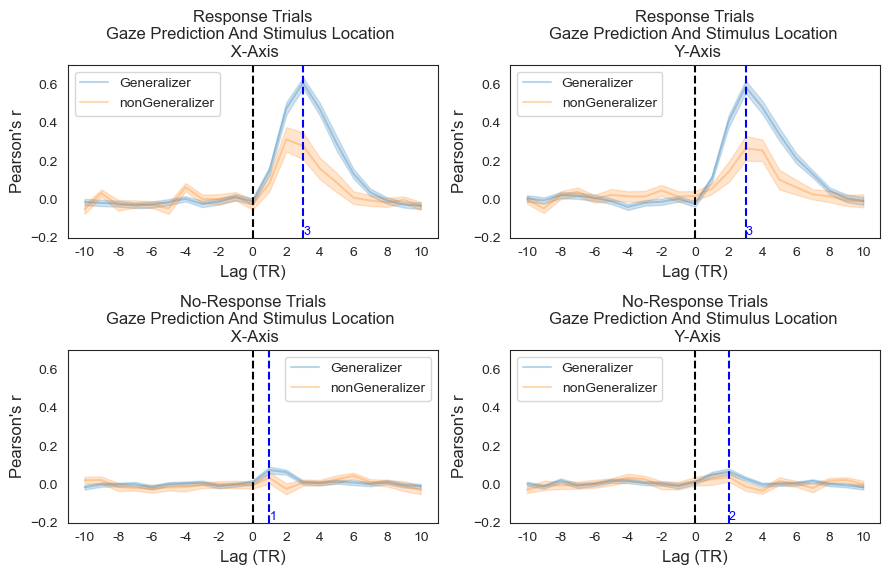

In [10]:
# plot mean correlation vs lag for each task events, for x and y separately, for each participant
for compute_method in ["median"]:# splitttype_lag_correlation_df_run_ave["compute_method"].unique():
    df = splitttype_lag_correlation_df[splitttype_lag_correlation_df.compute_method==compute_method].copy()
    
    
    
    if compute_method == "median":
        xlabel="Lag (TR)"
        xvar = "lag_TR"
        xticks = np.arange(-10,11,2)

        figdf = df.groupby(['subid','pretrainedmodel', 'taskname', "trial_type", 'compute_method',xvar])[['stimcorr_x', 'stimcorr_y']].mean().reset_index()
        figdf["subgroup"] = figdf["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
        #print(figdf.head())

    elif compute_method == "subTRsamples":
        xlabel="Lag (seconds)"
        xvar = "lag_sec"
        figdf = df.groupby(['subid','pretrainedmodel', 'taskname', "trial_type", 'compute_method',xvar])[['stimcorr_x', 'stimcorr_y']].mean().reset_index()
        figdf["subgroup"] = figdf["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
        #print(figdf.head())

        min_lag_s = figdf[xvar].min()
        max_lag_s = figdf[xvar].max()
        delta  = (max_lag_s - min_lag_s)/10
        xticks = np.arange(min_lag_s, max_lag_s+1, delta)

    xticklabels = [str(int(x)) for x in xticks]


    fig, axes = plt.subplots(2,2, figsize=(9,2*3),squeeze=False)
    for k, (ttype, ttypedf) in enumerate(figdf.groupby("trial_type")):
        axdf = ttypedf.copy()
        assert axdf["pretrainedmodel"].nunique() == 1, "More than one pretrained model found in the dataframe!"
        for j,correlation_type in enumerate(['stimcorr_x','stimcorr_y']):
            ax = axes[k,j]
            ax.set_ylim(-0.2,0.7)
            sns.lineplot(data=axdf, x=xvar, y=correlation_type, errorbar="se", hue="subgroup", ax=ax, alpha=0.3)
            ax.legend(title="")
            ax.axvline(x=0, color='black', linestyle='--')
            axtitle=f"{ttype}\ngaze prediction and stimulus Location \n {correlation_type[-1]}-axis"
            ax.set_title(axtitle.title())
            ax.set_xlabel(xlabel, fontsize=12)
            ax.set_ylabel("Pearson's r", fontsize=12)
            ax.set_xticks(xticks,labels=xticklabels)
            
            mean_corrs = axdf.groupby(xvar)[correlation_type].mean().values
            lags = axdf.groupby(xvar)[xvar].mean().values
            max_corr_idx = np.argmax(mean_corrs)
            max_corr_lag = lags[max_corr_idx]
            # mark the maximum correlation points using vertical lines
            ax.axvline(x=max_corr_lag, linestyle='--', color='blue')
            # add a text at the bottom of x-axis at the max_corr_lag position
            ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.1f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                    ha='left', va='bottom', fontsize=9, color='blue')
    #fig.suptitle(f"Decoding Consistency Lag Correlations - Compute Method: {compute_method}", fontsize=13, y =1)
    fig.suptitle("")
    fig.tight_layout()

In [11]:
axdf.shape[0]/56

21.0

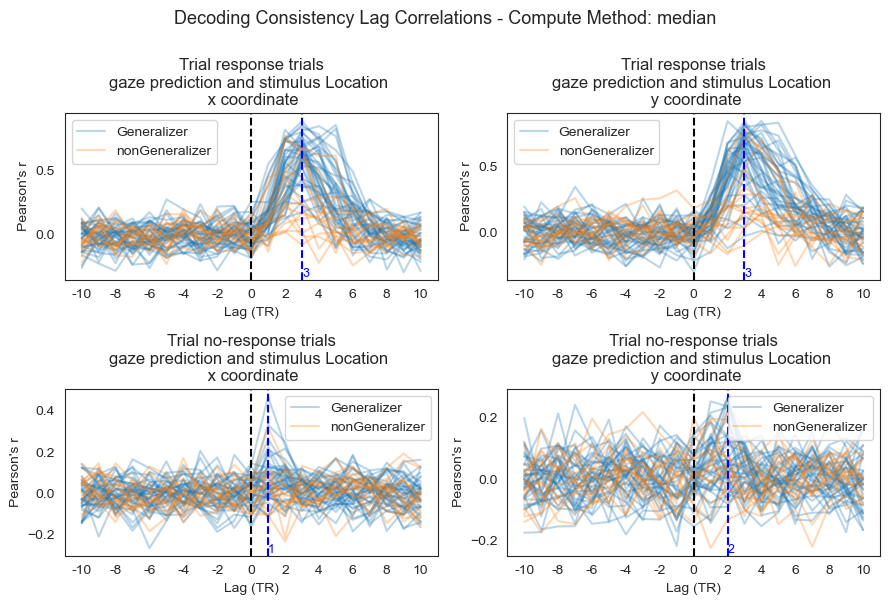

In [12]:
# plot mean correlation vs lag for each task events, for x and y separately, for each participant
for compute_method in ["median"]:# splitttype_lag_correlation_df_run_ave["compute_method"].unique():
    df = splitttype_lag_correlation_df[splitttype_lag_correlation_df.compute_method==compute_method].copy()
    
    if compute_method == "median":
        xlabel="Lag (TR)"
        xvar = "lag_TR"
        xticks = np.arange(-10,11,2)

        figdf = df.groupby(['subid','pretrainedmodel', 'taskname', "trial_type", 'compute_method',xvar])[['stimcorr_x', 'stimcorr_y']].mean().reset_index()
        figdf["subgroup"] = figdf["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
        #print(figdf.head())

    elif compute_method == "subTRsamples":
        xlabel="Lag (seconds)"
        xvar = "lag_sec"
        figdf = df.groupby(['subid','pretrainedmodel', 'taskname', "trial_type", 'compute_method',xvar])[['stimcorr_x', 'stimcorr_y']].mean().reset_index()
        figdf["subgroup"] = figdf["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
        #print(figdf.head())

        min_lag_s = figdf[xvar].min()
        max_lag_s = figdf[xvar].max()
        delta  = (max_lag_s - min_lag_s)/10
        xticks = np.arange(min_lag_s, max_lag_s+1, delta)

    xticklabels = [str(int(x)) for x in xticks]

    fig, axes = plt.subplots(2,2, figsize=(9,2*3),squeeze=False)
    for k, (ttype, ttypedf) in enumerate(figdf.groupby("trial_type")):
        axdf = ttypedf.copy()
        assert axdf["pretrainedmodel"].nunique() == 1, "More than one pretrained model found in the dataframe!"
        for j,correlation_type in enumerate(['stimcorr_x','stimcorr_y']):
            ax = axes[k,j]
            sns.lineplot(data=axdf, x=xvar, y=correlation_type, units="subid", estimator=None, hue="subgroup", ax=ax, alpha=0.3)
            ax.legend(title="")
            ax.axvline(x=0, color='black', linestyle='--')
            ax.set_title(f"Trial {ttype.replace('_', ' ')}\ngaze prediction and stimulus Location \n {correlation_type[-1]} coordinate")
            ax.set_xlabel(xlabel)
            ax.set_ylabel("Pearson's r")
            ax.set_xticks(xticks,labels=xticklabels)
            
            mean_corrs = axdf.groupby(xvar)[correlation_type].mean().values
            lags = axdf.groupby(xvar)[xvar].mean().values
            max_corr_idx = np.argmax(mean_corrs)
            max_corr_lag = lags[max_corr_idx]
            # mark the maximum correlation points using vertical lines
            ax.axvline(x=max_corr_lag, linestyle='--', color='blue')
            # add a text at the bottom of x-axis at the max_corr_lag position
            ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.1f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                    ha='left', va='bottom', fontsize=9, color='blue')
    fig.suptitle(f"Decoding Consistency Lag Correlations - Compute Method: {compute_method}", fontsize=13, y =1)
    fig.tight_layout()

In [13]:
splitttype_lag_correlation_df

,lag_TR,lag_sec,stimcorr_x,stimcorr_y,trial_type,subid,run,pretrainedmodel,taskname,max_stimcorr_lag_x,max_stimcorr_lag_y,compute_method,meandur_resp,meandur_stim,meandur_s2resp,subgroup
0,-10.0,-17.300,0.164850,-0.214236,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.000,5.000,median,8.006780,1.000708,9.007489,Generalizer
1,-9.0,-15.570,0.055611,0.023546,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.000,5.000,median,8.006780,1.000708,9.007489,Generalizer
2,-8.0,-13.840,-0.059030,0.159954,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.000,5.000,median,8.006780,1.000708,9.007489,Generalizer
3,-7.0,-12.110,-0.150535,-0.181324,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.000,5.000,median,8.006780,1.000708,9.007489,Generalizer
4,-6.0,-10.380,0.112652,-0.103141,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.000,5.000,median,8.006780,1.000708,9.007489,Generalizer
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99451,9.6,16.608,-0.022809,0.088868,no-response trials,sub130,4,m7_multiDS1to5,piratenavigation,11.418,2.768,subTRsamples,3.731124,1.000694,4.731818,Generalizer
99452,9.7,16.781,0.003807,0.099359,no-response trials,sub130,4,m7_multiDS1to5,piratenavigation,11.418,2.768,subTRsamples,3.731124,1.000694,4.731818,Generalizer
99453,9.8,16.954,0.027088,0.094144,no-response trials,sub130,4,m7_multiDS1to5,piratenavigation,11.418,2.768,subTRsamples,3.731124,1.000694,4.731818,Generalizer
99454,9.9,17.127,0.068017,0.063844,no-response trials,sub130,4,m7_multiDS1to5,piratenavigation,11.418,2.768,subTRsamples,3.731124,1.000694,4.731818,Generalizer


In [14]:
splitttype_lag_correlation_df.trial_type.unique()

['response trials', 'no-response trials']
Categories (2, object): ['response trials' < 'no-response trials']

In [ ]:
# select the row corresponding to the max correlation lag for each subject and in each run in splitttype_lag_correlation_df
max_lag_rows = [[],[]]
max_lag_acrossxy_rows = []
for (compute_method, subid, run), groupdf in splitttype_lag_correlation_df.groupby(['compute_method', 'subid', 'run']):
    # only select response trials
    resp_groupdf = groupdf[groupdf['trial_type']=='response trials'].copy()

    # check if number of rows in this df is sensible: should be 11 ( from 0TR to +10TR) for median, or 101 (from 0s to +10s with 0.1s step) for subTRsamples
    #expected_nrows = 11 if compute_method == "median" else 101
    #if resp_groupdf.shape[0] != expected_nrows:
    #    print(f"Warning: unexpected number of rows in groupdf for subid {subid}, run {run}, compute_method {compute_method}: {resp_groupdf.shape[0]} rows")
    #    continue

    # find the row with the maximum stimulus correlation (x and y separately)
    max_stimcorr_x_idx = resp_groupdf['stimcorr_x'].idxmax()
    max_stimcorr_y_idx = resp_groupdf['stimcorr_y'].idxmax()
    max_lag_rows[0].append(resp_groupdf.loc[max_stimcorr_x_idx])
    max_lag_rows[1].append(resp_groupdf.loc[max_stimcorr_y_idx])

    # select between max_stimcorr_x and max_stimcorr_y the one that has a larger lag_sec (no abs)
    if resp_groupdf.loc[max_stimcorr_x_idx]['lag_sec'] >= resp_groupdf.loc[max_stimcorr_y_idx]['lag_sec']:
        max_lag_acrossxy_rows.append(resp_groupdf.loc[max_stimcorr_x_idx])
    else:
        max_lag_acrossxy_rows.append(resp_groupdf.loc[max_stimcorr_y_idx])    

max_lag_corrs_df = pd.concat([pd.DataFrame(max_lag_rows[0]).assign(max_coord='x'), pd.DataFrame(max_lag_rows[1]).assign(max_coord='y')], ignore_index=True)
max_lag_corrs_df.reset_index(drop=True, inplace=True) # this is the dataframe that selects the max lag for x and y separately for each subject and run
max_lag_acrossxy_corrs_df = pd.DataFrame(max_lag_acrossxy_rows) # this is the dataframe that selects the max lag across x and y for each subject and run
max_lag_acrossxy_corrs_df.reset_index(drop=True, inplace=True)

In [16]:
import statsmodels.formula.api as smf
regdf = max_lag_acrossxy_corrs_df[max_lag_acrossxy_corrs_df.compute_method=="median"].copy()
regdf['meandur_s2resp_tr'] = regdf['meandur_s2resp'].values / pirate_defaults["fmri"]["tr"]

model = smf.mixedlm(
    "lag_TR ~ meandur_s2resp_tr *C(subgroup)",
    regdf,
    groups=regdf["subid"]
)
res = model.fit()
print(res.summary())


d:\miniconda3\envs\piratefmri\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
d:\miniconda3\envs\piratefmri\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2201: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


                          Mixed Linear Model Regression Results
Model:                         MixedLM            Dependent Variable:            lag_TR   
No. Observations:              224                Method:                        REML     
No. Groups:                    56                 Scale:                         3.7296   
Min. group size:               4                  Log-Likelihood:                -468.6336
Max. group size:               4                  Converged:                     Yes      
Mean group size:               4.0                                                        
------------------------------------------------------------------------------------------
                                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
------------------------------------------------------------------------------------------
Intercept                                        1.604    0.916  1.751 0.080 -0.192  3.399
C(subgroup)[T.nonGeneraliz

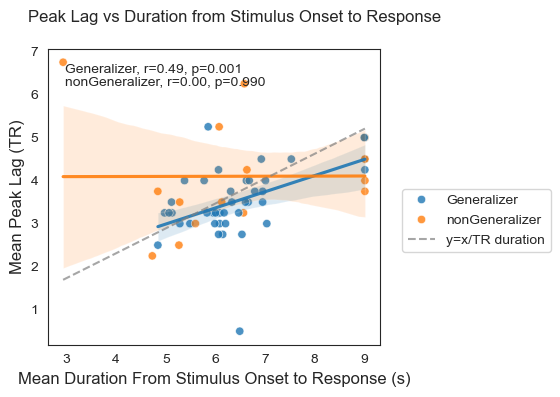

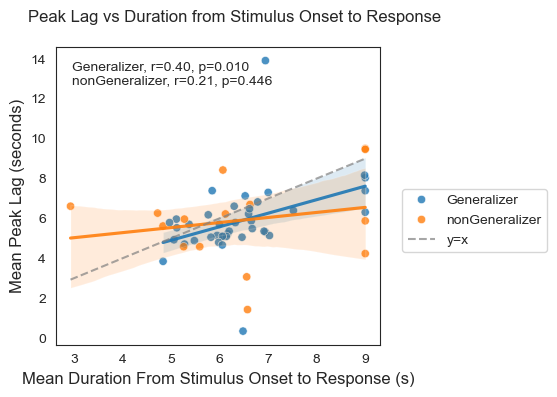

In [17]:
import scipy
import statsmodels.api as sm
# see if meandurs2resp is correlated with max_lag_sec in max_lag_acrossxy_corrs_df
color_pal = dict(zip(max_lag_acrossxy_corrs_df["subgroup"].unique(), sns.color_palette(None, n_colors=max_lag_acrossxy_corrs_df["subgroup"].nunique())))    
for i, compute_method in enumerate(max_lag_acrossxy_corrs_df["compute_method"].unique()):
    fig, ax = plt.subplots(1,1,figsize=(4,4))
    
    xunit = "TR" if compute_method=="median" else "seconds"
    yvar = "lag_TR" if compute_method=="median" else "lag_sec"
    
    max_lag_acrossxy_corrs_df_run_ave = max_lag_acrossxy_corrs_df.groupby(['subid', 'compute_method'])[[yvar,'meandur_s2resp']].mean().reset_index()
    max_lag_acrossxy_corrs_df_run_ave["subgroup"] = max_lag_acrossxy_corrs_df_run_ave["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
    
    
    
    subset_df = max_lag_acrossxy_corrs_df_run_ave[max_lag_acrossxy_corrs_df_run_ave.compute_method==compute_method].copy()
    sns.scatterplot(data=subset_df, x='meandur_s2resp', y=yvar, hue='subgroup', palette=color_pal, 
                    alpha=0.8,
                    ax=ax)
    
    # compute correlation for each subgroup
    inplot_text = ""
    for subgroup in subset_df["subgroup"].unique():
        subdf = subset_df[subset_df["subgroup"]==subgroup].copy()
        r,p = scipy.stats.pearsonr(subdf['meandur_s2resp'], subdf[yvar])
        inplot_text = inplot_text + f"\n{subgroup}, r={r:.2f}, p={p:.3f}"
        
        # compute regression coefficients and intercept with p-value
        #X = sm.add_constant(subdf['meandur_s2resp']/pirate_defaults["fmri"]["tr"])  if compute_method=="median" else sm.add_constant(subdf['meandur_s2resp'])  # adds the intercept term
        #model = sm.OLS(subdf[yvar], X)
        #results = model.fit()
        #intercept = results.params['const']
        #slope = results.params[1]
        #p_intercept = results.pvalues['const']
        #p_slope = results.pvalues[1]
        #annotate the slope and intercept with p-values
        #add_sig_asterisk = lambda p: '' if p>0.05 else ('*' if p>0.01 else ('**' if p>0.001 else '***'))
        #inplot_text = inplot_text + f"\n{subgroup}:\n slope={slope:.2f}{add_sig_asterisk(p_slope)}, intercept={intercept:.2f}{add_sig_asterisk(p_intercept)}"
        
        # plot regression line
        sns.regplot(data=subdf, x='meandur_s2resp', y=yvar, scatter=False, ax=ax,color=color_pal[subgroup], line_kws={"alpha":0.9},label=None)
    ax.text(0.05, 0.95, inplot_text.strip(), transform=ax.transAxes, fontsize=10, verticalalignment='top')
    # add y=x line, note that when xunit is TR, the yunit is also TR, so the line is y=x/trduration
    if compute_method == "median":
        trduration = pirate_defaults["fmri"]["tr"]  # seconds
        min_x = subset_df['meandur_s2resp'].min()
        max_x = subset_df['meandur_s2resp'].max()
        ax.plot([min_x, max_x], [min_x/trduration, max_x/trduration],
                      color='grey', linestyle='--', label='y=x/TR duration', alpha=0.7)
    else:
        min_x = subset_df['meandur_s2resp'].min()
        max_x = subset_df['meandur_s2resp'].max()
        ax.plot([min_x, max_x], [min_x, max_x],
                    color='grey', linestyle='--', label='y=x', alpha=0.7)
    title_text = f"Peak Lag vs Duration from Stimulus Onset to Response"
    ax.set_xlabel("Mean Duration From Stimulus Onset to Response (s)",fontsize=12)
    ax.set_ylabel(f"Mean Peak Lag ({xunit})",fontsize=12)
    # get unique legend entries
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    fig.legend(by_label.values(), by_label.keys(), title="", loc="upper left",bbox_to_anchor=(1, 0.55), ncol=1)
    ax.legend().set_visible(False)
    fig.suptitle(title_text, x=0.6)
    fig.tight_layout()

In [98]:
splitttype_lag_correlation_df.head(5)

,lag_TR,lag_sec,stimcorr_x,stimcorr_y,trial_type,subid,run,pretrainedmodel,taskname,max_stimcorr_lag_x,max_stimcorr_lag_y,compute_method,meandur_resp,meandur_stim,meandur_s2resp,subgroup
0,-10.0,-17.30,0.164850,-0.214236,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.0,5.0,median,8.00678,1.000708,9.007489,Generalizer
1,-9.0,-15.57,0.055611,0.023546,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.0,5.0,median,8.00678,1.000708,9.007489,Generalizer
2,-8.0,-13.84,-0.059030,0.159954,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.0,5.0,median,8.00678,1.000708,9.007489,Generalizer
3,-7.0,-12.11,-0.150535,-0.181324,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.0,5.0,median,8.00678,1.000708,9.007489,Generalizer
4,-6.0,-10.38,0.112652,-0.103141,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.0,5.0,median,8.00678,1.000708,9.007489,Generalizer


In [114]:
shuffled_lag_corrs = load(os.path.join(sttscorr_dir,f"shuffled_splittrialtypes_lag_corr.pkl"))
shuffled_lag_corrs.keys()


dict_keys(['response trials', 'no-response trials'])

In [ ]:
# pick the idx for generalizers and non-generalizers
gen_idx = [subid_list.index(subid) for subid in generalizers]
nongen_idx = [subid_list.index(subid) for subid in nongeneralizers]
shuffled_lag_corr_stat = {"Generalizer":{}, "nonGeneralizer":{}}
true_lag_corr_df = splitttype_lag_correlation_df[splitttype_lag_correlation_df["compute_method"]=="median"].copy()
for trial_type,shuffled_res in shuffled_lag_corrs.items():
    # shuffled_res is of shape (n_sub,n_runs,n_shuffles,n_lags, 2 for x and ys)
    print(trial_type, shuffled_res.shape)
    # compute the group mean at each shuffle and each lag and x/y for generalizers and non-generalizers
    shuffled_res_gen_mean_perrun = shuffled_res[gen_idx,:,:,:,:].mean(axis=0)  # shape (n_runs,n_shuffles,n_lags,2)
    shuffled_res_nongen_mean_perrun = shuffled_res[nongen_idx,:,:,:,:].mean(axis=0)  # shape (n_runs,n_shuffles,n_lags,2)
    print(f"Generalizers mean shuffled correlation shape: {shuffled_res_gen_mean_perrun.shape}")
    print(f"Non-Generalizers mean shuffled correlation shape: {shuffled_res_nongen_mean_perrun.shape}")
    # compute the group mean across runs for generalizers and non-generalizers
    shuffled_res_gen_mean_acrossruns = shuffled_res_gen_mean_perrun.mean(axis=0)  # shape (n_shuffles,n_lags,2)
    shuffled_res_nongen_mean_acrossruns = shuffled_res_nongen_mean_perrun.mean(axis=0)  # shape (n_shuffles,n_lags,2)
    print(f"Generalizers mean shuffled correlation shape: {shuffled_res_gen_mean_acrossruns.shape}")
    print(f"Non-Generalizers mean shuffled correlation shape: {shuffled_res_nongen_mean_acrossruns.shape}")
    # compare the true results with the shuffled results and compute the p-value at each lag for generalizers and non-generalizers
    true_gen_corrs = true_lag_corr_df[(true_lag_corr_df["trial_type"]==trial_type) & (true_lag_corr_df["subgroup"]=="Generalizer")].groupby("lag_TR")[['stimcorr_x','stimcorr_y']].mean().values  # shape (n_lags,2)
    true_nongen_corrs = true_lag_corr_df[(true_lag_corr_df["trial_type"]==trial_type) & (true_lag_corr_df["subgroup"]=="nonGeneralizer")].groupby("lag_TR")[['stimcorr_x','stimcorr_y']].mean().values  # shape (n_lags,2)
    shuffled_lag_corr_stat["Generalizer"][trial_type] = np.mean(shuffled_res_gen_mean_acrossruns >= true_gen_corrs, axis=0)  # shape (n_lags,2)
    shuffled_lag_corr_stat["nonGeneralizer"][trial_type] = np.mean(shuffled_res_nongen_mean_acrossruns >= true_nongen_corrs, axis=0)  # shape (n_lags,2)

# do multiple comparison correction using FDR across lags for each group and trial type
shuffled_lag_corr_stat_corrected = {"Generalizer":{}, "nonGeneralizer":{}}
from statsmodels.stats.multitest import fdrcorrection
for group in shuffled_lag_corr_stat.keys():
    for trial_type in shuffled_lag_corr_stat[group].keys():
        pvals = shuffled_lag_corr_stat[group][trial_type]  # shape (n_lags,2)
        pvals = pvals.flatten()  # shape (n_lags*2,)
        _, pvals_corrected = fdrcorrection(pvals,is_sorted=False,method="poscorr")
        # put back into the original shape
        shuffled_lag_corr_stat_corrected[group][trial_type] = {
            "pvals": pvals.reshape(-1,2),
            "pvals_corrected": pvals_corrected.reshape(-1,2)
        }


response trials (56, 4, 1000, 21, 2)
Generalizers mean shuffled correlation shape: (4, 1000, 21, 2)
Non-Generalizers mean shuffled correlation shape: (4, 1000, 21, 2)
Generalizers mean shuffled correlation shape: (1000, 21, 2)
Non-Generalizers mean shuffled correlation shape: (1000, 21, 2)
no-response trials (56, 4, 1000, 21, 2)
Generalizers mean shuffled correlation shape: (4, 1000, 21, 2)
Non-Generalizers mean shuffled correlation shape: (4, 1000, 21, 2)
Generalizers mean shuffled correlation shape: (1000, 21, 2)
Non-Generalizers mean shuffled correlation shape: (1000, 21, 2)


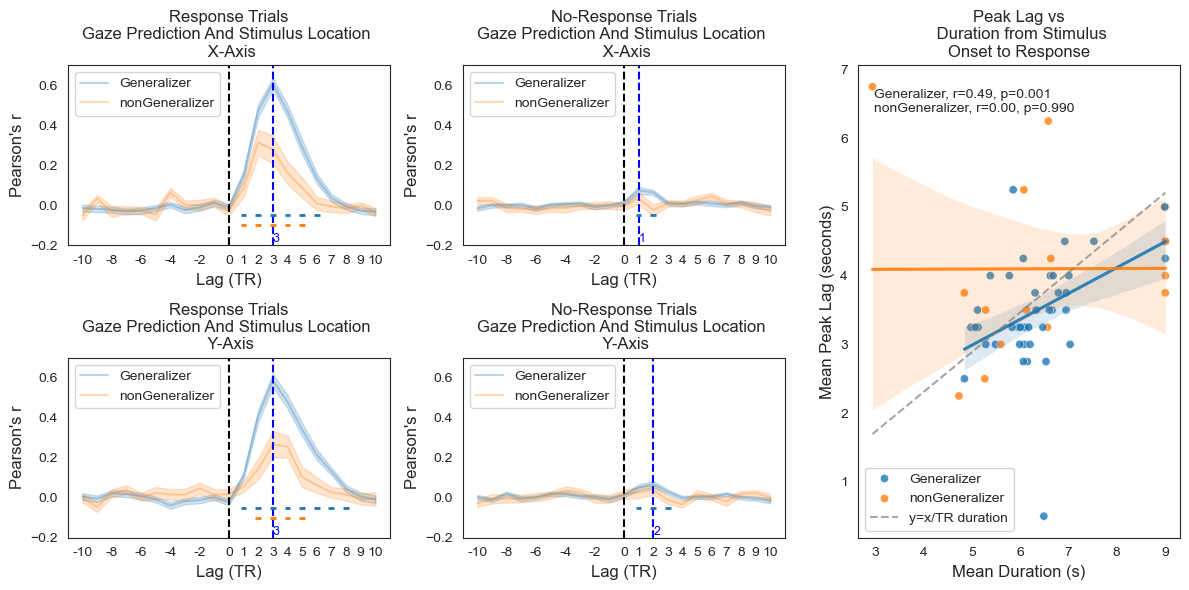

In [ ]:
# re-do the plots in one figure
compute_method = "median"
    
df = splitttype_lag_correlation_df[splitttype_lag_correlation_df.compute_method==compute_method].copy()
subgroup_color_pal = dict(zip(df["subgroup"].unique(), sns.color_palette(None, n_colors=df["subgroup"].nunique())))
if compute_method == "median":
    xlabel="Lag (TR)"
    xvar = "lag_TR"
    xticks = np.concatenate([np.arange(-10,0,2), np.arange(0,11,1)])

    figdf = df.groupby(['subid','pretrainedmodel', 'taskname', "trial_type", 'compute_method',xvar])[['stimcorr_x', 'stimcorr_y']].mean().reset_index()
    figdf["subgroup"] = figdf["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
    #print(figdf.head())

elif compute_method == "subTRsamples":
    xlabel="Lag (seconds)"
    xvar = "lag_sec"
    figdf = df.groupby(['subid','pretrainedmodel', 'taskname', "trial_type", 'compute_method',xvar])[['stimcorr_x', 'stimcorr_y']].mean().reset_index()
    figdf["subgroup"] = figdf["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
    #print(figdf.head())

    min_lag_s = figdf[xvar].min()
    max_lag_s = figdf[xvar].max()
    delta  = (max_lag_s - min_lag_s)/10
    xticks = np.arange(min_lag_s, max_lag_s+1, delta)

xticklabels = [str(int(x)) for x in xticks]

from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(12,2*3))
gs = GridSpec(2, 3, width_ratios=[1,1,1], height_ratios=[1,1])
axes = [[fig.add_subplot(gs[0,0]), fig.add_subplot(gs[0,1])],
        [fig.add_subplot(gs[1,0]), fig.add_subplot(gs[1,1])],
        [fig.add_subplot(gs[:,2])]]


for k, (ttype, ttypedf) in enumerate(figdf.groupby("trial_type")):
    axdf = ttypedf.copy()
    assert axdf["pretrainedmodel"].nunique() == 1, "More than one pretrained model found in the dataframe!"
    for j,correlation_type in enumerate(['stimcorr_x','stimcorr_y']):
        ax = axes[j][k]
        ax.set_ylim(-0.2,0.7)
        sns.lineplot(data=axdf, x=xvar, y=correlation_type, errorbar="se", hue="subgroup", palette=subgroup_color_pal, ax=ax, alpha=0.3)
        ax.legend(title="")
        ax.axvline(x=0, color='black', linestyle='--')
        axtitle=f"{ttype}\ngaze prediction and stimulus Location \n {correlation_type[-1]}-axis"
        ax.set_title(axtitle.title())
        ax.set_xlabel(xlabel, fontsize=12)
        ax.set_ylabel("Pearson's r", fontsize=12)
        ax.set_xticks(xticks,labels=xticklabels)
        
        mean_corrs = axdf.groupby(xvar)[correlation_type].mean().values
        lags = axdf.groupby(xvar)[xvar].mean().values
        max_corr_idx = np.argmax(mean_corrs)
        max_corr_lag = lags[max_corr_idx]
        # mark the maximum correlation points using vertical lines
        ax.axvline(x=max_corr_lag, linestyle='--', color='blue')
        # add a text at the bottom of x-axis at the max_corr_lag position
        ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.1f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                ha='left', va='bottom', fontsize=9, color='blue')
        
        # mark statistical test results
        pval_g = shuffled_lag_corr_stat_corrected["Generalizer"][ttype]["pvals_corrected"][:,j]
        pval_ng = shuffled_lag_corr_stat_corrected["nonGeneralizer"][ttype]["pvals_corrected"][:,j]
        
        for lag, p_g, p_ng in zip(lags, pval_g, pval_ng):
            p_g_str = gen_pval_annot(p_g, show_pval=False)
            p_ng_str = gen_pval_annot(p_ng, show_pval=False)
            #ax.text(lag, -.05, p_g_str, color=subgroup_color_pal.get("Generalizer", 'black'))
            #ax.text(lag, -.1, p_ng_str, color=subgroup_color_pal.get("nonGeneralizer", 'black'))
            # add horizontal lines to indicate significance
            if p_g < 0.05:
                ax.hlines(-0.05, lag-0.2, lag+0.2, color=subgroup_color_pal.get("Generalizer", 'black'), linewidth=2)
            if p_ng < 0.05:
                ax.hlines(-0.1, lag-0.2, lag+0.2, color=subgroup_color_pal.get("nonGeneralizer", 'black'), linewidth=2)



color_pal = dict(zip(max_lag_acrossxy_corrs_df["subgroup"].unique(), sns.color_palette(None, n_colors=max_lag_acrossxy_corrs_df["subgroup"].nunique())))    
ax = axes[2][0]
yvar = "lag_TR" if compute_method=="median" else "lag_sec"
max_lag_acrossxy_corrs_df_run_ave = max_lag_acrossxy_corrs_df.groupby(['subid', 'compute_method'])[[yvar,'meandur_s2resp']].mean().reset_index()
max_lag_acrossxy_corrs_df_run_ave["subgroup"] = max_lag_acrossxy_corrs_df_run_ave["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")



subset_df = max_lag_acrossxy_corrs_df_run_ave[max_lag_acrossxy_corrs_df_run_ave.compute_method==compute_method].copy()
sns.scatterplot(data=subset_df, x='meandur_s2resp', y=yvar, hue='subgroup', palette=color_pal, 
                alpha=0.8,
                ax=ax)

# compute correlation for each subgroup
inplot_text = ""
for subgroup in subset_df["subgroup"].unique():
    subdf = subset_df[subset_df["subgroup"]==subgroup].copy()
    r,p = scipy.stats.pearsonr(subdf['meandur_s2resp'], subdf[yvar])
    inplot_text = inplot_text + f"\n{subgroup}, r={r:.2f}, p={p:.3f}"
    
    # compute regression coefficients and intercept with p-value
    #X = sm.add_constant(subdf['meandur_s2resp']/pirate_defaults["fmri"]["tr"])  if compute_method=="median" else sm.add_constant(subdf['meandur_s2resp'])  # adds the intercept term
    #model = sm.OLS(subdf[yvar], X)
    #results = model.fit()
    #intercept = results.params['const']
    #slope = results.params[1]
    #p_intercept = results.pvalues['const']
    #p_slope = results.pvalues[1]
    #annotate the slope and intercept with p-values
    #add_sig_asterisk = lambda p: '' if p>0.05 else ('*' if p>0.01 else ('**' if p>0.001 else '***'))
    #inplot_text = inplot_text + f"\n{subgroup}:\n slope={slope:.2f}{add_sig_asterisk(p_slope)}, intercept={intercept:.2f}{add_sig_asterisk(p_intercept)}"
    
    # plot regression line
    sns.regplot(data=subdf, x='meandur_s2resp', y=yvar, scatter=False, ax=ax,color=color_pal[subgroup], line_kws={"alpha":0.9},label=None)
ax.text(0.05, 0.95, inplot_text.strip(), transform=ax.transAxes, fontsize=10, verticalalignment='top')
# add y=x line, note that when xunit is TR, the yunit is also TR, so the line is y=x/trduration
if compute_method == "median":
    trduration = pirate_defaults["fmri"]["tr"]  # seconds
    min_x = subset_df['meandur_s2resp'].min()
    max_x = subset_df['meandur_s2resp'].max()
    ax.plot([min_x, max_x], [min_x/trduration, max_x/trduration],
                    color='grey', linestyle='--', label='y=x/TR duration', alpha=0.7)
else:
    min_x = subset_df['meandur_s2resp'].min()
    max_x = subset_df['meandur_s2resp'].max()
    ax.plot([min_x, max_x], [min_x, max_x],
                color='grey', linestyle='--', label='y=x', alpha=0.7)
title_text = f"Peak Lag vs\n Duration from Stimulus\nOnset to Response"
ax.set_xlabel("Mean Duration (s)",fontsize=12)
ax.set_ylabel(f"Mean Peak Lag ({xunit})",fontsize=12)
ax.set_ylabel(f"Mean Peak Lag ({xunit})",fontsize=12)
ax.set_ylabel(f"Mean Peak Lag ({xunit})",fontsize=12)
# get unique legend entries
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), title="", loc="lower left", 
          bbox_to_anchor=(0,0.0), ncol=1,frameon=True)
ax.set_title(title_text, x=0.5)

#fig.suptitle(f"Decoding Consistency Lag Correlations - Compute Method: {compute_method}", fontsize=13, y =1)
fig.tight_layout()
fig.savefig(os.path.join(ROIRSAdir,"finalfigs","figS7d-f.tif"),dpi=300,bbox_inches="tight")    



In [218]:
# Plot the Z statistics instead of correlation
gen_idx = [subid_list.index(subid) for subid in generalizers]
nongen_idx = [subid_list.index(subid) for subid in nongeneralizers]
shuffled_lag_Z_stat = {"Generalizer":{}, "nonGeneralizer":{}}
true_lag_corr_df = splitttype_lag_correlation_df[splitttype_lag_correlation_df["compute_method"]=="median"].copy()
true_lag_corr_df["Zstimcorr_x"] = np.arctanh(true_lag_corr_df["stimcorr_x"])
true_lag_corr_df["Zstimcorr_y"] = np.arctanh(true_lag_corr_df["stimcorr_y"])
for trial_type,shuffled_res in shuffled_lag_corrs.items():
    # shuffled_res is of shape (n_sub,n_runs,n_shuffles,n_lags, 2 for x and ys)
    print(trial_type, shuffled_res.shape)
    # transform in to z-statistics
    shuffled_res_z = np.arctanh(shuffled_res)
    # take the max z across all the lags, so we have (n_sub,n_runs,n_shuffles, 2 for x and ys)
    max_shuffled_res_z = np.max(shuffled_res_z, axis=3)  # shape (n_sub,n_runs,n_shuffles, 2)
    print(f"Max shuffled correlation shape: {max_shuffled_res_z.shape}")

    # compute the mean for each group, so each group should have shape (n_shuffles, 2)
    shuffled_maxz_gen_mean_acrossruns = max_shuffled_res_z[gen_idx,:,:,:].mean(axis=(0,1))  # shape (n_shuffles, 2)
    shuffled_maxz_nongen_mean_acrossruns = max_shuffled_res_z[nongen_idx,:,:,:].mean(axis=(0,1))  # shape (n_shuffles, 2)
    print(shuffled_maxz_gen_mean_acrossruns.shape)

    # get the true results at each lag (n_lag,2)
    true_gen_corrs = true_lag_corr_df[(true_lag_corr_df["trial_type"]==trial_type) & (true_lag_corr_df["subgroup"]=="Generalizer")].groupby("lag_TR")[['Zstimcorr_x','Zstimcorr_y']].mean().values  # shape (n_lags,2)
    true_nongen_corrs = true_lag_corr_df[(true_lag_corr_df["trial_type"]==trial_type) & (true_lag_corr_df["subgroup"]=="nonGeneralizer")].groupby("lag_TR")[['Zstimcorr_x','Zstimcorr_y']].mean().values  # shape (n_lags,2)
    # compare the true results with te shuffled results and compute teh p-value at each lag for G and nG
    # the shape of shuffled_maxz_gen_mean_acrossruns is (n_shuffles, 2), and the shape of true_gen_corrs is (n_lags,2)
    # this means that we are using the same null for each lag, i.e., each lag should be compared to the same null to get a result of shape (n_lags,2)
    shuffled_lag_Z_stat["Generalizer"][trial_type] = np.array([np.mean(shuffled_maxz_gen_mean_acrossruns >= true_gen_lag_corr, axis=0) for true_gen_lag_corr in true_gen_corrs])
    shuffled_lag_Z_stat["nonGeneralizer"][trial_type] = np.array([np.mean(shuffled_maxz_nongen_mean_acrossruns >= true_nongen_lag_corr, axis=0) for true_nongen_lag_corr in true_nongen_corrs])


# do multiple comparison correction using FDR across lags for each group and trial type
shuffled_lag_Z_stat_corrected = {"Generalizer":{}, "nonGeneralizer":{}}
from statsmodels.stats.multitest import fdrcorrection, multipletests
for group in shuffled_lag_Z_stat.keys():
    for trial_type in shuffled_lag_Z_stat[group].keys():
        pvals = shuffled_lag_Z_stat[group][trial_type]  # shape (n_lags,2)
        pvals = pvals.flatten()  # shape (n_lags*2,)
        _, pvals_corrected, _, _ = multipletests(pvals, alpha=0.05, method='holm')
        # put back into the original shape
        shuffled_lag_Z_stat_corrected[group][trial_type] = {
            "pvals": pvals.reshape(-1,2),
            "pvals_corrected": pvals_corrected.reshape(-1,2)
        }

response trials (56, 4, 1000, 21, 2)
Max shuffled correlation shape: (56, 4, 1000, 2)
(1000, 2)
no-response trials (56, 4, 1000, 21, 2)
Max shuffled correlation shape: (56, 4, 1000, 2)
(1000, 2)


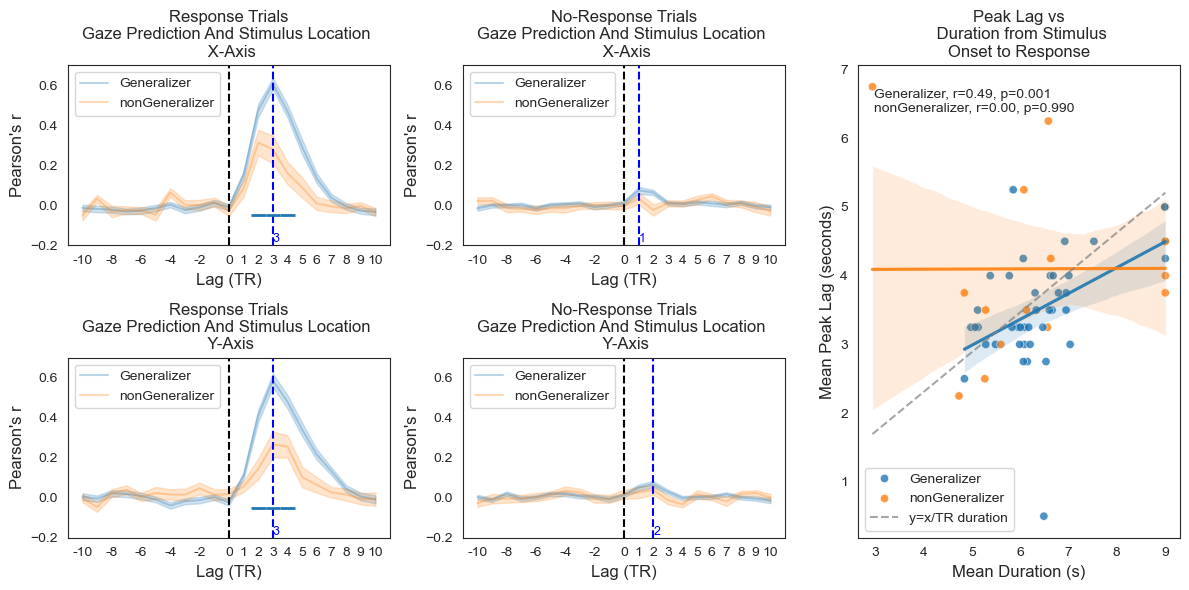

In [219]:
# re-do the plots in one figure
compute_method = "median"
    
df = splitttype_lag_correlation_df[splitttype_lag_correlation_df.compute_method==compute_method].copy()
subgroup_color_pal = dict(zip(df["subgroup"].unique(), sns.color_palette(None, n_colors=df["subgroup"].nunique())))
if compute_method == "median":
    xlabel="Lag (TR)"
    xvar = "lag_TR"
    xticks = np.concatenate([np.arange(-10,0,2), np.arange(0,11,1)])

    figdf = df.groupby(['subid','pretrainedmodel', 'taskname', "trial_type", 'compute_method',xvar])[['stimcorr_x', 'stimcorr_y']].mean().reset_index()
    figdf["subgroup"] = figdf["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
    #print(figdf.head())

elif compute_method == "subTRsamples":
    xlabel="Lag (seconds)"
    xvar = "lag_sec"
    figdf = df.groupby(['subid','pretrainedmodel', 'taskname', "trial_type", 'compute_method',xvar])[['stimcorr_x', 'stimcorr_y']].mean().reset_index()
    figdf["subgroup"] = figdf["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
    #print(figdf.head())

    min_lag_s = figdf[xvar].min()
    max_lag_s = figdf[xvar].max()
    delta  = (max_lag_s - min_lag_s)/10
    xticks = np.arange(min_lag_s, max_lag_s+1, delta)

xticklabels = [str(int(x)) for x in xticks]

from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(12,2*3))
gs = GridSpec(2, 3, width_ratios=[1,1,1], height_ratios=[1,1])
axes = [[fig.add_subplot(gs[0,0]), fig.add_subplot(gs[0,1])],
        [fig.add_subplot(gs[1,0]), fig.add_subplot(gs[1,1])],
        [fig.add_subplot(gs[:,2])]]


for k, (ttype, ttypedf) in enumerate(figdf.groupby("trial_type")):
    axdf = ttypedf.copy()
    assert axdf["pretrainedmodel"].nunique() == 1, "More than one pretrained model found in the dataframe!"
    for j,correlation_type in enumerate(['stimcorr_x','stimcorr_y']):
        ax = axes[j][k]
        ax.set_ylim(-0.2,0.7)
        sns.lineplot(data=axdf, x=xvar, y=correlation_type, errorbar="se", hue="subgroup", palette=subgroup_color_pal, ax=ax, alpha=0.3)
        ax.legend(title="")
        ax.axvline(x=0, color='black', linestyle='--')
        axtitle=f"{ttype}\ngaze prediction and stimulus Location \n {correlation_type[-1]}-axis"
        ax.set_title(axtitle.title())
        ax.set_xlabel(xlabel, fontsize=12)
        ax.set_ylabel("Pearson's r", fontsize=12)
        ax.set_xticks(xticks,labels=xticklabels)
        
        mean_corrs = axdf.groupby(xvar)[correlation_type].mean().values
        lags = axdf.groupby(xvar)[xvar].mean().values
        max_corr_idx = np.argmax(mean_corrs)
        max_corr_lag = lags[max_corr_idx]
        # mark the maximum correlation points using vertical lines
        ax.axvline(x=max_corr_lag, linestyle='--', color='blue')
        # add a text at the bottom of x-axis at the max_corr_lag position
        ax.text(max_corr_lag, ax.get_ylim()[0], f"{max_corr_lag:.1f}" if compute_method=="subTRsamples" else f"{int(max_corr_lag)}" , 
                ha='left', va='bottom', fontsize=9, color='blue')
        
        # mark statistical test results
        pval_g = shuffled_lag_Z_stat_corrected["Generalizer"][ttype]["pvals_corrected"][:,j]
        pval_ng = shuffled_lag_Z_stat_corrected["nonGeneralizer"][ttype]["pvals_corrected"][:,j]
        
        for lag, p_g, p_ng in zip(lags, pval_g, pval_ng):
            if p_g < 0.05:
                ax.hlines(-0.05, lag-0.5, lag+0.5, color=subgroup_color_pal.get("Generalizer", 'black'), linewidth=2)
            if p_ng < 0.05:
                ax.hlines(-0.1, lag-0.5, lag+0.5, color=subgroup_color_pal.get("nonGeneralizer", 'black'), linewidth=2)



color_pal = dict(zip(max_lag_acrossxy_corrs_df["subgroup"].unique(), sns.color_palette(None, n_colors=max_lag_acrossxy_corrs_df["subgroup"].nunique())))    
ax = axes[2][0]
yvar = "lag_TR" if compute_method=="median" else "lag_sec"
max_lag_acrossxy_corrs_df_run_ave = max_lag_acrossxy_corrs_df.groupby(['subid', 'compute_method'])[[yvar,'meandur_s2resp']].mean().reset_index()
max_lag_acrossxy_corrs_df_run_ave["subgroup"] = max_lag_acrossxy_corrs_df_run_ave["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")



subset_df = max_lag_acrossxy_corrs_df_run_ave[max_lag_acrossxy_corrs_df_run_ave.compute_method==compute_method].copy()
sns.scatterplot(data=subset_df, x='meandur_s2resp', y=yvar, hue='subgroup', palette=color_pal, 
                alpha=0.8,
                ax=ax)

# compute correlation for each subgroup
inplot_text = ""
for subgroup in subset_df["subgroup"].unique():
    subdf = subset_df[subset_df["subgroup"]==subgroup].copy()
    r,p = scipy.stats.pearsonr(subdf['meandur_s2resp'], subdf[yvar])
    inplot_text = inplot_text + f"\n{subgroup}, r={r:.2f}, p={p:.3f}"
    
    # plot regression line
    sns.regplot(data=subdf, x='meandur_s2resp', y=yvar, scatter=False, ax=ax,color=color_pal[subgroup], line_kws={"alpha":0.9},label=None)
ax.text(0.05, 0.95, inplot_text.strip(), transform=ax.transAxes, fontsize=10, verticalalignment='top')
# add y=x line, note that when xunit is TR, the yunit is also TR, so the line is y=x/trduration
if compute_method == "median":
    trduration = pirate_defaults["fmri"]["tr"]  # seconds
    min_x = subset_df['meandur_s2resp'].min()
    max_x = subset_df['meandur_s2resp'].max()
    ax.plot([min_x, max_x], [min_x/trduration, max_x/trduration],
                    color='grey', linestyle='--', label='y=x/TR duration', alpha=0.7)
else:
    min_x = subset_df['meandur_s2resp'].min()
    max_x = subset_df['meandur_s2resp'].max()
    ax.plot([min_x, max_x], [min_x, max_x],
                color='grey', linestyle='--', label='y=x', alpha=0.7)
title_text = f"Peak Lag vs\n Duration from Stimulus\nOnset to Response"
ax.set_xlabel("Mean Duration (s)",fontsize=12)
ax.set_ylabel(f"Mean Peak Lag ({xunit})",fontsize=12)
ax.set_ylabel(f"Mean Peak Lag ({xunit})",fontsize=12)
ax.set_ylabel(f"Mean Peak Lag ({xunit})",fontsize=12)
# get unique legend entries
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), title="", loc="lower left", 
          bbox_to_anchor=(0,0.0), ncol=1,frameon=True)
ax.set_title(title_text, x=0.5)

#fig.suptitle(f"Decoding Consistency Lag Correlations - Compute Method: {compute_method}", fontsize=13, y =1)
fig.tight_layout()
fig.savefig(os.path.join(ROIRSAdir,"finalfigs","figS7d-f.tif"),dpi=300,bbox_inches="tight")    



In [19]:
max_lag_corrs_df

,lag_TR,lag_sec,stimcorr_x,stimcorr_y,trial_type,subid,run,pretrainedmodel,taskname,max_stimcorr_lag_x,max_stimcorr_lag_y,compute_method,meandur_resp,meandur_stim,meandur_s2resp,subgroup,max_coord
0,5.0,8.650,0.840928,0.723812,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.000,5.000,median,8.006780,1.000708,9.007489,Generalizer,x
1,5.0,8.650,0.856926,0.648781,response trials,sub001,2,m7_multiDS1to5,piratenavigation,5.000,4.000,median,8.006814,1.000701,9.007515,Generalizer,x
2,5.0,8.650,0.891029,0.665603,response trials,sub001,3,m7_multiDS1to5,piratenavigation,5.000,5.000,median,8.006819,1.000698,9.007517,Generalizer,x
3,5.0,8.650,0.871379,0.740090,response trials,sub001,4,m7_multiDS1to5,piratenavigation,5.000,5.000,median,8.006808,1.000706,9.007514,Generalizer,x
4,-9.0,-15.570,0.425591,-0.009453,response trials,sub002,1,m7_multiDS1to5,piratenavigation,-9.000,1.000,median,8.006812,1.000702,9.007515,nonGeneralizer,x
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
891,3.0,5.190,-0.114237,0.331603,response trials,sub129,4,m7_multiDS1to5,piratenavigation,6.747,5.190,subTRsamples,0.865215,1.000694,1.865909,Generalizer,y
892,2.4,4.152,0.703535,0.707601,response trials,sub130,1,m7_multiDS1to5,piratenavigation,4.498,4.152,subTRsamples,4.961315,1.000698,5.962013,Generalizer,y
893,0.5,0.865,-0.152923,0.581385,response trials,sub130,2,m7_multiDS1to5,piratenavigation,6.401,0.865,subTRsamples,4.121392,1.000700,5.122092,Generalizer,y
894,1.8,3.114,0.303314,0.831332,response trials,sub130,3,m7_multiDS1to5,piratenavigation,3.979,3.114,subTRsamples,3.436921,1.000697,4.437618,Generalizer,y


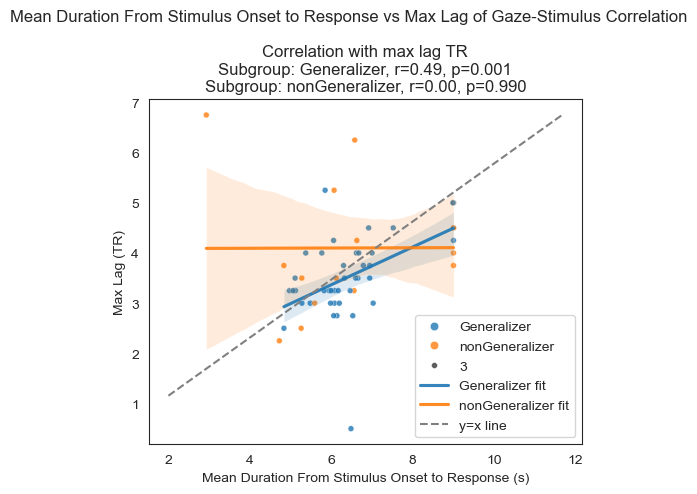

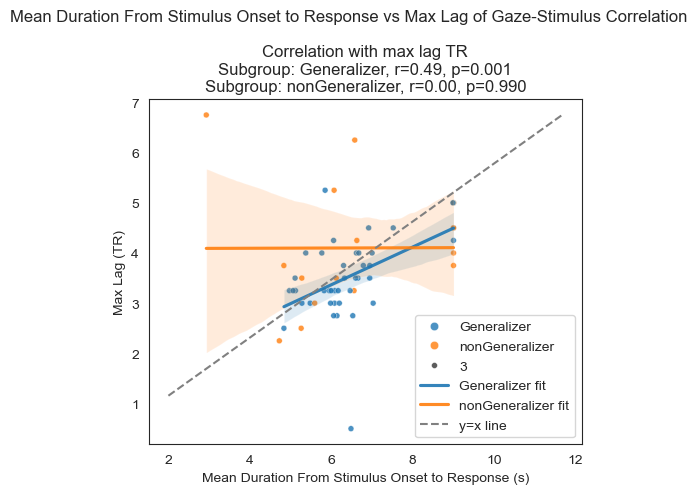

In [20]:
# see if meandurs2resp is correlated with max_lag_sec in max_lag_acrossxy_corrs_df
import scipy
# see if meandurs2resp is correlated with max_lag_sec in max_lag_acrossxy_corrs_df
for compute_method in ["median","subTRsamples"]:
    max_lag_acrossxy_corrs_df_run_ave = max_lag_acrossxy_corrs_df.groupby(['subid', 'compute_method'])[['meandur_s2resp','lag_TR']].mean().reset_index()
    max_lag_acrossxy_corrs_df_run_ave["subgroup"] = max_lag_acrossxy_corrs_df_run_ave["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
        
    fig, ax = plt.subplots(1,1,figsize=(5,5))
    color_pal = dict(zip(max_lag_acrossxy_corrs_df_run_ave["subgroup"].unique(), sns.color_palette(None, n_colors=len(max_lag_acrossxy_corrs_df_run_ave["subgroup"].unique()))))    
    subset_df = max_lag_acrossxy_corrs_df_run_ave[max_lag_acrossxy_corrs_df_run_ave.compute_method=="median"].copy()
    subset_df["lag_TR_proxysec"] = subset_df["lag_TR"] * pirate_defaults["fmri"]["tr"]  # assuming TR=1.73s
    sns.scatterplot(data=subset_df, x='meandur_s2resp', y='lag_TR_proxysec', hue='subgroup', palette=color_pal, 
                    size=3,alpha=0.8,
                    ax=ax)

    # compute correlation for each subgroup
    title_text = f"Correlation with max lag TR"
    for subgroup in subset_df["subgroup"].unique():
        subdf = subset_df[subset_df["subgroup"]==subgroup].copy()
        r,p = scipy.stats.pearsonr(subdf['meandur_s2resp'], subdf['lag_TR_proxysec'])
        title_text = title_text + f"\nSubgroup: {subgroup}, r={r:.2f}, p={p:.3f}"
        # plot regression line
        sns.regplot(data=subdf, x='meandur_s2resp', y='lag_TR_proxysec', scatter=False, ax=ax, 
                    label=f"{subgroup} fit",color=color_pal[subgroup], line_kws={"alpha":0.9})
    ax.set_yticks((np.arange(8)+1)*pirate_defaults["fmri"]["tr"],
                labels=(np.arange(8)+1))
    # plot a diagonal line y=x
    ax.plot([2, max(subset_df['meandur_s2resp'].max(), subset_df['lag_TR_proxysec'].max())],
            [2, max(subset_df['meandur_s2resp'].max(), subset_df['lag_TR_proxysec'].max())],
            linestyle='--', color='grey', label='y=x line')
    ax.set_title(title_text)
    ax.set_xlabel("Mean Duration From Stimulus Onset to Response (s)")
    ax.set_ylabel(f"Max Lag (TR)")
    ax.legend(title="")
    fig.suptitle("Mean Duration From Stimulus Onset to Response vs Max Lag of Gaze-Stimulus Correlation")
    fig.tight_layout()

# Correlation with neural results

In [142]:
# select the row corresponding to the max correlation lag for each subject and in each run in splitttype_lag_correlation_df
max_lag_rows = [[],[]]
max_lag_acrossxy_rows = []
for (compute_method, subid, run, trial_type), groupdf in splitttype_lag_correlation_df.groupby(['compute_method', 'subid', 'run','trial_type']):
    # only compute_method == "median"
    if compute_method == "median":
        # find the row with the maximum stimulus correlation (x and y separately)
        max_stimcorr_x_idx = groupdf['stimcorr_x'].idxmax()
        max_stimcorr_y_idx = groupdf['stimcorr_y'].idxmax()
        max_lag_rows[0].append(groupdf.loc[max_stimcorr_x_idx])
        max_lag_rows[1].append(groupdf.loc[max_stimcorr_y_idx])

        # select between max_stimcorr_x and max_stimcorr_y the one that has a larger lag_sec (no abs)
        if groupdf.loc[max_stimcorr_x_idx]['lag_sec'] >= groupdf.loc[max_stimcorr_y_idx]['lag_sec']:
            max_lag_acrossxy_rows.append(groupdf.loc[max_stimcorr_x_idx])
        else:
            max_lag_acrossxy_rows.append(groupdf.loc[max_stimcorr_y_idx])    

max_corrs_xysep_df = pd.concat([pd.DataFrame(max_lag_rows[0]).assign(max_coord='x'), pd.DataFrame(max_lag_rows[1]).assign(max_coord='y')], ignore_index=True)
max_corrs_xysep_df.reset_index(drop=True, inplace=True) # this is the dataframe that selects the max lag for x and y separately for each subject and run
max_corrs_acrossxy_df = pd.DataFrame(max_lag_acrossxy_rows) # this is the dataframe that selects the max lag across x and y for each subject and run
max_corrs_acrossxy_df.reset_index(drop=True, inplace=True)


In [143]:
# we take the max_lag_acrossxy_corrs_df which has the max lag (the larger one across x and y) and consistency correlation for x y at this max lag
# this dataframe has nsub*nruns*trialtype rows, we have 2 trialtypes (with or without response), so each sub has 4*2=8 rows
# compute the mean of x and y corr
max_corrs_acrossxy_df["mean_stimcorr"] = max_corrs_acrossxy_df[["stimcorr_x","stimcorr_y"]].mean(axis=1)
display(max_corrs_acrossxy_df)
# take the average across runs for each subject, this dataframe has nsub*trialtype rows, we have 2 trialtypes (with or without response), so each sub has 4*2=8 rows
max_corrs_acrossxy_df_run_ave = max_corrs_acrossxy_df.groupby(['subid', 'trial_type'])[['lag_TR','lag_sec','mean_stimcorr','meandur_s2resp']].mean().reset_index()
max_corrs_acrossxy_df_run_ave["subgroup"] = max_corrs_acrossxy_df_run_ave["subid"].apply(lambda x: "Generalizer" if x in generalizers else "nonGeneralizer")
max_corrs_acrossxy_df_run_ave

,lag_TR,lag_sec,stimcorr_x,stimcorr_y,trial_type,subid,run,pretrainedmodel,taskname,max_stimcorr_lag_x,max_stimcorr_lag_y,compute_method,meandur_resp,meandur_stim,meandur_s2resp,subgroup,mean_stimcorr
0,5.0,8.65,0.840928,0.723812,response trials,sub001,1,m7_multiDS1to5,piratenavigation,5.0,5.0,median,8.006780,1.000708,9.007489,Generalizer,0.782370
1,10.0,17.30,0.237286,-0.115411,no-response trials,sub001,1,m7_multiDS1to5,piratenavigation,10.0,-1.0,median,8.006780,1.000708,9.007489,Generalizer,0.060937
2,5.0,8.65,0.856926,0.648781,response trials,sub001,2,m7_multiDS1to5,piratenavigation,5.0,4.0,median,8.006814,1.000701,9.007515,Generalizer,0.752854
3,3.0,5.19,0.191952,0.022165,no-response trials,sub001,2,m7_multiDS1to5,piratenavigation,3.0,-7.0,median,8.006814,1.000701,9.007515,Generalizer,0.107058
4,5.0,8.65,0.891029,0.665603,response trials,sub001,3,m7_multiDS1to5,piratenavigation,5.0,5.0,median,8.006819,1.000698,9.007517,Generalizer,0.778316
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
443,6.0,10.38,0.218474,0.116214,no-response trials,sub130,2,m7_multiDS1to5,piratenavigation,6.0,-7.0,median,4.121392,1.000700,5.122092,Generalizer,0.167344
444,3.0,5.19,0.364115,0.470069,response trials,sub130,3,m7_multiDS1to5,piratenavigation,3.0,2.0,median,3.436921,1.000697,4.437618,Generalizer,0.417092
445,-5.0,-8.65,0.304252,0.076576,no-response trials,sub130,3,m7_multiDS1to5,piratenavigation,-5.0,-9.0,median,3.436921,1.000697,4.437618,Generalizer,0.190414
446,3.0,5.19,0.483821,0.601848,response trials,sub130,4,m7_multiDS1to5,piratenavigation,3.0,2.0,median,3.731124,1.000694,4.731818,Generalizer,0.542835


,subid,trial_type,lag_TR,lag_sec,mean_stimcorr,meandur_s2resp,subgroup
0,sub001,no-response trials,7.50,12.9750,0.120201,9.007509,Generalizer
1,sub001,response trials,5.00,8.6500,0.779818,9.007509,Generalizer
2,sub002,no-response trials,6.25,10.8125,0.137007,9.007519,nonGeneralizer
3,sub002,response trials,3.75,6.4875,0.280306,9.007519,nonGeneralizer
4,sub003,no-response trials,2.75,4.7575,0.162128,6.082962,Generalizer
...,...,...,...,...,...,...,...
107,sub128,response trials,4.25,7.3525,0.660527,6.060250,Generalizer
108,sub129,no-response trials,0.00,0.0000,0.121696,5.122286,Generalizer
109,sub129,response trials,3.25,5.6225,0.580067,5.122286,Generalizer
110,sub130,no-response trials,1.25,2.1625,0.157011,5.063385,Generalizer


### correlation between peak consistency with low-d composition in V1 and PPC

In [144]:
retrivepat_res = load(os.path.join(ROIRSAdir,"retrievalpatternCV","resoverview","retrievalpatternCV_results.pkl"))


compositionretrieval_resdf = retrivepat_res["results"].copy()
#compositionretrieval_resdf = compositionretrieval_resdf[~compositionretrieval_resdf.subid.isin (["sub129","sub010"])].copy()  # remove sub129 who has incomplete data
compositionretrieval_resdf[["analysis","metricname"]] = compositionretrieval_resdf.metric.str.split("-",expand=True)
compositionretrieval_resdf["region"] = [x.split("_")[0] for x in compositionretrieval_resdf.roi]


compositionretrieval_resdf["subgroup"] = pd.Categorical(
    ["Generalizer" if subid in generalizers else "nonGeneralizer" for subid in compositionretrieval_resdf["subid"]],
    categories=["Generalizer","nonGeneralizer"],ordered=True    
)

# filter out the low-D composition results (i.e., correlation with distmod regressor in the retrieval pattern CV analysis)
# this data frame has nsub*nROI (5) rows
lowdcompo_res = compositionretrieval_resdf[(compositionretrieval_resdf.metricname.isin(['reg_distmod']))].copy()
lowdcompo_res

,value,metric,roi,subid,analysis,metricname,region,subgroup
8,-0.121605,train2test-reg_distmod,PPC_bilateral,sub001,train2test,reg_distmod,PPC,Generalizer
27,-0.005641,train2test-reg_distmod,PPC_bilateral,sub002,train2test,reg_distmod,PPC,nonGeneralizer
46,0.114544,train2test-reg_distmod,PPC_bilateral,sub003,train2test,reg_distmod,PPC,Generalizer
65,0.116817,train2test-reg_distmod,PPC_bilateral,sub004,train2test,reg_distmod,PPC,nonGeneralizer
84,0.237139,train2test-reg_distmod,PPC_bilateral,sub005,train2test,reg_distmod,PPC,Generalizer
...,...,...,...,...,...,...,...,...
5233,-0.140392,train2test-reg_distmod,M1_left,sub125,train2test,reg_distmod,M1,Generalizer
5252,-0.026189,train2test-reg_distmod,M1_left,sub127,train2test,reg_distmod,M1,Generalizer
5271,0.017220,train2test-reg_distmod,M1_left,sub128,train2test,reg_distmod,M1,Generalizer
5290,0.132714,train2test-reg_distmod,M1_left,sub129,train2test,reg_distmod,M1,Generalizer


In [145]:
# join the max_corrs_acrossxy_df_run_ave with lowdcompo_res on subid and subgroup, to see if the max lag of gaze-stimulus correlation is related to the low-D composition retrieval performance
lag_corr_compolowD_df = pd.merge(
    max_corrs_acrossxy_df_run_ave[["subid","subgroup","trial_type","mean_stimcorr"]],
    lowdcompo_res[["subid","subgroup","region","value"]].rename(columns={"value":"lowDcompo_reg_distmod_corr"}),
    on=["subid","subgroup"],
    how="inner"
)
lag_corr_compolowD_df = lag_corr_compolowD_df[lag_corr_compolowD_df.region.isin(["V1","PPC"])].copy() # only focus on the region that has low-D composition
lag_corr_compolowD_df

,subid,subgroup,trial_type,mean_stimcorr,region,lowDcompo_reg_distmod_corr
0,sub001,Generalizer,no-response trials,0.120201,PPC,-0.121605
1,sub001,Generalizer,no-response trials,0.120201,V1,-0.036856
5,sub001,Generalizer,response trials,0.779818,PPC,-0.121605
6,sub001,Generalizer,response trials,0.779818,V1,-0.036856
10,sub002,nonGeneralizer,no-response trials,0.137007,PPC,-0.005641
...,...,...,...,...,...,...
546,sub129,Generalizer,response trials,0.580067,V1,0.113236
550,sub130,Generalizer,no-response trials,0.157011,PPC,0.348639
551,sub130,Generalizer,no-response trials,0.157011,V1,0.089405
555,sub130,Generalizer,response trials,0.534189,PPC,0.348639


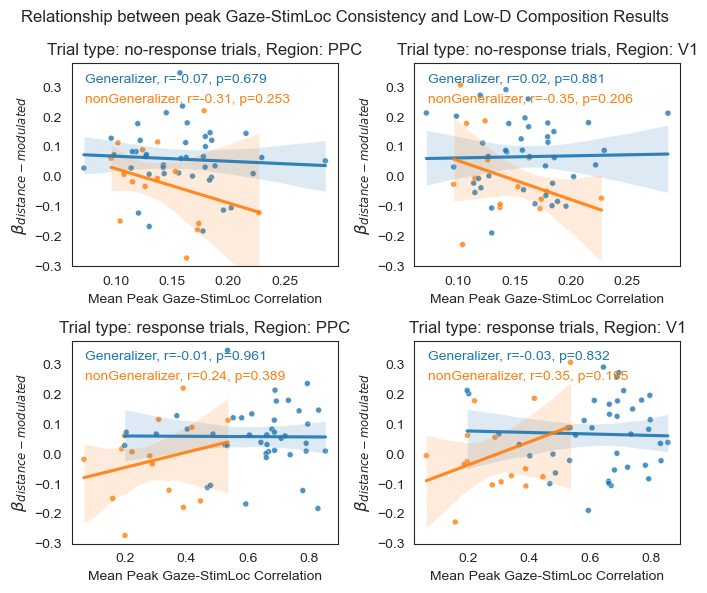

In [161]:
fig, axes = plt.subplots(2,2,figsize=(7,6))    
for j, ((trial_type,region), groupdf) in enumerate(lag_corr_compolowD_df.groupby(['trial_type','region'])):
    ax = axes.flatten()[j]
    color_pal = dict(zip(groupdf["subgroup"].unique(), sns.color_palette(None, n_colors=len(groupdf["subgroup"].unique()))))    
    sns.scatterplot(data=groupdf, x='mean_stimcorr', y='lowDcompo_reg_distmod_corr', hue='subgroup', 
                    palette=color_pal, 
                    size=3,alpha=0.8,
                    ax=ax)
    ax.legend().remove()
    title_text = f"Trial type: {trial_type}, Region: {region}"
    ax.set_title(title_text)
    
    # compute correlation for each subgroup
    for k, subgroup in enumerate(groupdf["subgroup"].unique()):
        subdf = groupdf[groupdf["subgroup"]==subgroup].copy()
        r,p = scipy.stats.pearsonr(subdf['mean_stimcorr'], subdf['lowDcompo_reg_distmod_corr'])
        corr_text = f"{subgroup}, r={r:.2f}, p={p:.3f}"
        # plot regression line
        sns.regplot(data=subdf, x='mean_stimcorr', y='lowDcompo_reg_distmod_corr', scatter=False, ax=ax, 
                    color=color_pal[subgroup], line_kws={"alpha":0.9})
        ax.text(0.05, 0.95-k*0.1, corr_text.strip(), transform=ax.transAxes, fontsize=10, verticalalignment='top',color=color_pal[subgroup])
    ax.set_xlabel("Mean Peak Gaze-StimLoc Correlation")
    ax.set_ylabel(r'$\beta_{distance-modulated}$', fontsize=12)
    ax.set_ylim(-0.3,0.38)
    
fig.suptitle("Relationship between peak Gaze-StimLoc Consistency and Low-D Composition Results")
fig.tight_layout() 

### correlation between peak consistency with rsa

In [ ]:
withintask_rsa_df = pd.read_csv(os.path.join(ROIRSAdir,"withintaskrsa","rsa_withintask.csv"))
withintask_rsa_df
# filter out the low-D rsa results (i.e., correlation with gtlocEuclidean regressor in the RSA analysis)
# this data frame has nsub*nROI (5) rows
lowdrsa_res = withintask_rsa_df[(withintask_rsa_df.modelrdm.isin(['modelrdm'])) & (withintask_rsa_df.analysis.isin(['test stim Compete high low D']))].copy()
lowdrsa_res

,modelrdm,coefficient,roi,subid,subgroup,taskname,analysis,adjR2,R2
0,gtlocEuclidean,0.054332,V1_bilateral,sub001,Generalizer,navigation,all Compete Feature Cartesian,0.042859,0.046060
1,feature,0.186695,V1_bilateral,sub001,Generalizer,navigation,all Compete Feature Cartesian,0.042859,0.046060
2,gtlocEuclidean,0.133729,V1_bilateral,sub001,Generalizer,navigation,all Cartesian,NaN,NaN
3,feature,0.189592,V1_bilateral,sub001,Generalizer,navigation,all feature,NaN,NaN
4,gtlocEuclidean,0.147230,V1_bilateral,sub001,Generalizer,navigation,train stim withinxy - Euc,NaN,NaN
...,...,...,...,...,...,...,...,...,...
4475,feature,0.111471,M1_left,sub130,Generalizer,navigation,test stim high D,NaN,NaN
4476,gtlocEuclidean,0.073051,M1_left,sub130,Generalizer,localizer,all Compete Feature Cartesian,-0.022559,0.006657
4477,feature,0.029299,M1_left,sub130,Generalizer,localizer,all Compete Feature Cartesian,-0.022559,0.006657
4478,gtlocEuclidean,0.050705,M1_left,sub130,Generalizer,localizer,all Cartesian,NaN,NaN


In [157]:
lowdrsa_res = withintask_rsa_df[(withintask_rsa_df.modelrdm.isin(['gtlocEuclidean'])) & (withintask_rsa_df.analysis.isin(['test stim Compete high low D']))].copy()
lowdrsa_res["region"] = [x.split("_")[0] for x in lowdrsa_res.roi]
lowdrsa_res

,modelrdm,coefficient,roi,subid,subgroup,taskname,analysis,adjR2,R2,region
6,gtlocEuclidean,0.071335,V1_bilateral,sub001,Generalizer,navigation,test stim Compete high low D,0.067010,0.074850,V1
22,gtlocEuclidean,0.065670,V1_bilateral,sub002,nonGeneralizer,navigation,test stim Compete high low D,0.043118,0.051160,V1
38,gtlocEuclidean,0.140677,V1_bilateral,sub003,Generalizer,navigation,test stim Compete high low D,0.156576,0.163663,V1
54,gtlocEuclidean,0.064753,V1_bilateral,sub004,nonGeneralizer,navigation,test stim Compete high low D,0.080528,0.088254,V1
70,gtlocEuclidean,-0.056533,V1_bilateral,sub005,Generalizer,navigation,test stim Compete high low D,0.078323,0.086069,V1
...,...,...,...,...,...,...,...,...,...,...
4406,gtlocEuclidean,0.058222,M1_left,sub125,Generalizer,navigation,test stim Compete high low D,-0.002829,0.005598,M1
4422,gtlocEuclidean,0.201291,M1_left,sub127,Generalizer,navigation,test stim Compete high low D,0.057339,0.065260,M1
4438,gtlocEuclidean,-0.036028,M1_left,sub128,Generalizer,navigation,test stim Compete high low D,-0.007376,0.001089,M1
4454,gtlocEuclidean,0.210177,M1_left,sub129,Generalizer,navigation,test stim Compete high low D,0.033449,0.041572,M1


In [158]:
# join the max_corrs_acrossxy_df_run_ave with lowdrsa_res on subid and subgroup, to see if the max lag of gaze-stimulus correlation is related to the low-D RSA
lag_corr_rsalowD_df = pd.merge(
    max_corrs_acrossxy_df_run_ave[["subid","subgroup","trial_type","mean_stimcorr"]],
    lowdrsa_res[["subid","subgroup","region","coefficient"]],
    on=["subid","subgroup"],
    how="inner"
)
lag_corr_rsalowD_df = lag_corr_rsalowD_df[lag_corr_rsalowD_df.region.isin(["V1","PPC"])].copy() # only focus on the region that has low-D RSA
lag_corr_rsalowD_df

,subid,subgroup,trial_type,mean_stimcorr,region,coefficient
0,sub001,Generalizer,no-response trials,0.120201,V1,0.071335
1,sub001,Generalizer,no-response trials,0.120201,PPC,0.071822
5,sub001,Generalizer,response trials,0.779818,V1,0.071335
6,sub001,Generalizer,response trials,0.779818,PPC,0.071822
10,sub002,nonGeneralizer,no-response trials,0.137007,V1,0.065670
...,...,...,...,...,...,...
546,sub129,Generalizer,response trials,0.580067,PPC,0.191616
550,sub130,Generalizer,no-response trials,0.157011,V1,-0.046878
551,sub130,Generalizer,no-response trials,0.157011,PPC,0.040838
555,sub130,Generalizer,response trials,0.534189,V1,-0.046878


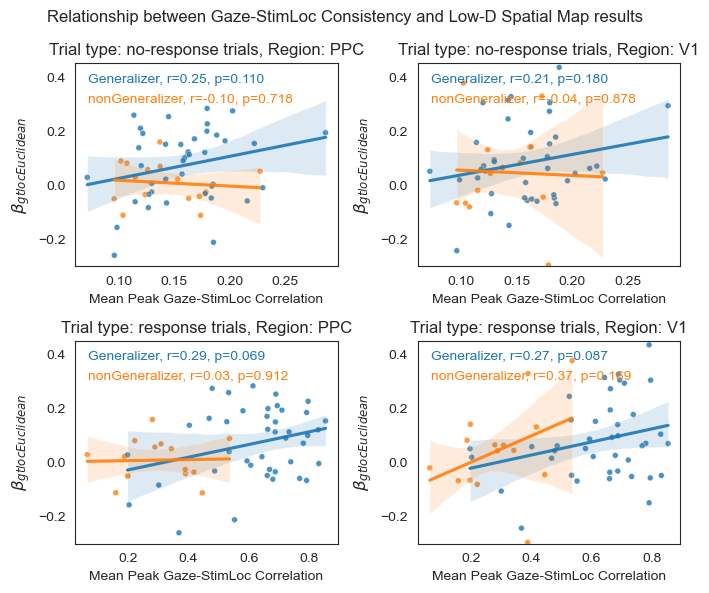

In [212]:
fig, axes = plt.subplots(2,2,figsize=(7,6))    
for j, ((trial_type,region), groupdf) in enumerate(lag_corr_rsalowD_df.groupby(['trial_type','region'])):
    ax = axes.flatten()[j]
    color_pal = dict(zip(groupdf["subgroup"].unique(), sns.color_palette(None, n_colors=len(groupdf["subgroup"].unique()))))    
    sns.scatterplot(data=groupdf, x='mean_stimcorr', y='coefficient', hue='subgroup', 
                    palette=color_pal, 
                    size=3,alpha=0.8,
                    ax=ax)
    ax.legend().remove()
    title_text = f"Trial type: {trial_type}, Region: {region}"
    ax.set_title(title_text)
    
    # compute correlation for each subgroup
    for k, subgroup in enumerate(groupdf["subgroup"].unique()):
        subdf = groupdf[groupdf["subgroup"]==subgroup].copy()
        r,p = scipy.stats.pearsonr(subdf['mean_stimcorr'], subdf['coefficient'])
        corr_text = f"{subgroup}, r={r:.2f}, p={p:.3f}"
        # plot regression line
        sns.regplot(data=subdf, x='mean_stimcorr', y='coefficient', scatter=False, ax=ax, 
                    color=color_pal[subgroup], line_kws={"alpha":0.9})
        ax.text(0.05, 0.95-k*0.1, corr_text.strip(), transform=ax.transAxes, fontsize=10, verticalalignment='top',color=color_pal[subgroup])
    ax.set_xlabel("Mean Peak Gaze-StimLoc Correlation")
    ax.set_ylabel(r'$\beta_{gtlocEuclidean}$', fontsize=12)
    ax.set_ylim(-0.3,0.45)
    
fig.suptitle("Relationship between Gaze-StimLoc Consistency and Low-D Spatial Map results")
fig.tight_layout() 